In [1]:
## first cell 

# CS 179 Final Project: Bayesian PMF on MovieLens 1M

**Group Members:** Kevin Chen, Michael Cherian Thomas, Suyash Jain  
**Date:** June 2025  

**Objective:**  
1. Fit a simple Bayesian “user–item bias” PGM to MovieLens 100K and compute test‐set RMSE.  
2. Fit a Bayesian PMF (probabilistic matrix factorization) with K latent factors.  
3. Sweep over K ∈ {5,10,20,50} and training‐set fraction ∈ {0.2,0.5,0.8}; plot how RMSE and training time change.  

In [2]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO
from pyro.optim import Adam
from pyro.infer.autoguide import AutoDiagonalNormal

# Fix random seeds
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
pyro.set_rng_seed(random_seed)


## 1  Data Preparation

Load, inspect, and split the MovieLens 100K ratings (943 users, 1682 movies, 100 000 ratings).  

In [3]:
# Unzip the MovieLens 1M data into ml-1m/
!unzip ml-1m.zip -d ml-1m

# Move files up one level if they’re nested
!mv ml-1m/ml-1m/* ml-1m/
!rmdir ml-1m/ml-1m

# List the contents to confirm
!ls -1 ml-1m

Archive:  ml-1m.zip
   creating: ml-1m/ml-1m/
  inflating: ml-1m/ml-1m/movies.dat  
  inflating: ml-1m/ml-1m/ratings.dat  
  inflating: ml-1m/ml-1m/README      
  inflating: ml-1m/ml-1m/users.dat   
README
movies.dat
ratings.dat
users.dat


In [4]:
import os
import pandas as pd

# Load MovieLens 1M ratings data
data_file = "ml-1m/ratings.dat"
print("File found:", os.path.exists(data_file))

# Read the data into a DataFrame
df = pd.read_csv(
    data_file,
    sep="::",
    names=["userId", "movieId", "rating", "timestamp"],
    engine="python"
)

# Basic checks
print("Total entries:", df.shape[0], "rows and", df.shape[1], "columns")
print(
    "Unique users:", df["userId"].nunique(),
    "| Unique movies:", df["movieId"].nunique()
)

# Display the first few rows
df.head()

File found: True
Total entries: 1000209 rows and 4 columns
Unique users: 6040 | Unique movies: 3706


,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


*Train Other Models*

In [5]:
# Convert user and movie IDs to zero-based indices
orig_users = df['userId'].unique()
user_map = {old: idx for idx, old in enumerate(orig_users)}
df['userId'] = df['userId'].map(user_map)

orig_movies = df['movieId'].unique()
movie_map = {old: idx for idx, old in enumerate(orig_movies)}
df['movieId'] = df['movieId'].map(movie_map)

# Split into 80% train and 20% test sets
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=random_seed
)
print(f"Training samples: {len(train_df)}; Testing samples: {len(test_df)}")

# Display a few examples from each set
print("Sample training records:")
display(train_df.sample(3, random_state=random_seed))
print("Sample testing records:")
display(test_df.sample(3, random_state=random_seed))

# Save the splits for exact reproducibility
train_df.to_csv('train.csv', index=False)
test_df.to_csv('test.csv', index=False)

Training samples: 800167; Testing samples: 200042
Sample training records:


,userId,movieId,rating,timestamp
26773,189,86,3,977028506
708607,4249,2550,4,965308627
730966,4372,729,5,965177950


Sample testing records:


,userId,movieId,rating,timestamp
463045,2856,59,4,972511121
189068,1171,790,3,974867608
890623,5375,1578,5,960409841


In [6]:
# 1. Determine number of users and movies from the full DataFrame
num_users = df['userId'].nunique()
num_movies = df['movieId'].nunique()
Nu = num_users
Ni = num_movies
print(f"Number of users: {Nu}, Number of movies: {Ni}")

# 2. Define the baseline bias model in Pyro
def bias_model(user_ids, item_ids, ratings):
    # Global mean
    mu = pyro.param("mu", torch.tensor(3.0))
    # User and movie biases
    bu = pyro.param("bu", torch.zeros(Nu))
    bi = pyro.param("bi", torch.zeros(Ni))
    # Observation noise
    sigma = pyro.param(
        "sigma", torch.tensor(1.0),
        constraint=dist.constraints.positive
    )

    # Model each rating
    with pyro.plate("data", len(ratings)):
        u = user_ids.long()
        i = item_ids.long()
        prediction = mu + bu[u] + bi[i]
        pyro.sample(
            "obs",
            dist.Normal(prediction, sigma),
            obs=ratings.float()
        )

# 3. Prepare train/test tensors for SVI and evaluation
t_train = torch.tensor(train_df['userId'].values, dtype=torch.long)
i_train = torch.tensor(train_df['movieId'].values, dtype=torch.long)
r_train = torch.tensor(train_df['rating'].values, dtype=torch.float)

t_test = torch.tensor(test_df['userId'].values, dtype=torch.long)
i_test = torch.tensor(test_df['movieId'].values, dtype=torch.long)
r_test = torch.tensor(test_df['rating'].values, dtype=torch.float)

# 4. Set up SVI inference
pyro.clear_param_store()
optimizer = Adam({"lr": 1e-2})
def bias_guide(user_ids, item_ids, ratings):
    # No latent random variables here; parameters only
    pass

svi = SVI(bias_model, bias_guide, optimizer, loss=Trace_ELBO())

# 5. Run SVI for 200 steps with progress output
print("Training baseline bias model...")
for step in range(1, 201):
    loss = svi.step(t_train, i_train, r_train)
    if step % 50 == 0:
        print(f"  Step {step} / 200, Loss = {loss:.2f}")

# 6. Compute test-set RMSE manually
mu_hat = pyro.param("mu").item()
bu_hat = pyro.param("bu").detach()
bi_hat = pyro.param("bi").detach()

squared_error = 0.0
for idx in range(len(r_test)):
    u = t_test[idx]
    i = i_test[idx]
    pred = mu_hat + bu_hat[u] + bi_hat[i]
    err = pred - r_test[idx]
    squared_error += err.item() ** 2
baseline_rmse = (squared_error / len(r_test)) ** 0.5
print(f"Baseline Model RMSE: {baseline_rmse:.4f}")

Number of users: 6040, Number of movies: 3706
Training baseline bias model...
  Step 50 / 200, Loss = 1094270.00
  Step 100 / 200, Loss = 1054490.50
  Step 150 / 200, Loss = 1048480.69
  Step 200 / 200, Loss = 1047493.38
Baseline Model RMSE: 0.9120


In [7]:
# PMF Model (K = 10) 
import time
# 1. Choose number of latent factors
K = 10
pyro.clear_param_store()
# 3. Define the PMF generative model
def pmf_model(user_ids, item_ids, ratings):
    sigma_u = pyro.param("sigma_u", torch.tensor(1.0), constraint=dist.constraints.positive)
    sigma_v = pyro.param("sigma_v", torch.tensor(1.0), constraint=dist.constraints.positive)
    sigma_r = pyro.param("sigma_r", torch.tensor(1.0), constraint=dist.constraints.positive)

    with pyro.plate("users", Nu):
        U = pyro.sample("U", dist.Normal(torch.zeros(K), sigma_u * torch.ones(K)).to_event(1))
    with pyro.plate("items", Ni):
        V = pyro.sample("V", dist.Normal(torch.zeros(K), sigma_v * torch.ones(K)).to_event(1))
    with pyro.plate("data", len(ratings)):
        u = user_ids.long()
        i = item_ids.long()
        pred = (U[u] * V[i]).sum(-1)
        pyro.sample("obs", dist.Normal(pred, sigma_r), obs=ratings.float())

# 4. Set up guide and SVI
guide = AutoDiagonalNormal(pmf_model)
svi   = SVI(pmf_model, guide, Adam({"lr": 5e-3}), loss=Trace_ELBO())

# 5. Run SVI for 300 steps, printing progress
print(f"Training PMF model with K={K} factors...")
start_time = time.time()
for step in range(1, 301):
    loss = svi.step(t_train, i_train, r_train)
    if step % 100 == 0:
        print(f"  Step {step}/300  Loss = {loss:.1f}")
elapsed = time.time() - start_time
print(f"PMF training completed in {elapsed:.1f} seconds.\n")

# 6. Extract posterior means
U_loc = guide.median()["U"].detach()
V_loc = guide.median()["V"].detach()

# 7. Compute RMSE on the test set with an explicit loop
sse = 0.0
for idx in range(len(r_test)):
    u_idx = t_test[idx].item()
    i_idx = i_test[idx].item()
    true_r = r_test[idx].item()
    pred_r = (U_loc[u_idx] * V_loc[i_idx]).sum().item()
    sse += (pred_r - true_r) ** 2

pmf_rmse = (sse / len(r_test)) ** 0.5
print(f"PMF Model (K={K}) RMSE on Test Set: {pmf_rmse:.4f}")

Training PMF model with K=10 factors...
  Step 100/300  Loss = 1599903.4
  Step 200/300  Loss = 1334141.9
  Step 300/300  Loss = 1299501.9
PMF training completed in 10.0 seconds.

PMF Model (K=10) RMSE on Test Set: 0.9381


Starting hyperparameter sweep over latent dimension K...

=== K = 5 ===
  Training step 100/300, loss = 2120899.2
  Training step 200/300, loss = 1316351.6
  Training step 300/300, loss = 1274073.8
  Finished in 8.6 sec
  RMSE at K=5: 0.9312

=== K = 10 ===
  Training step 100/300, loss = 1612539.7
  Training step 200/300, loss = 1335731.2
  Training step 300/300, loss = 1301151.3
  Finished in 10.2 sec
  RMSE at K=10: 0.9386

=== K = 20 ===
  Training step 100/300, loss = 1511394.9
  Training step 200/300, loss = 1400446.9
  Training step 300/300, loss = 1349474.7
  Finished in 13.9 sec
  RMSE at K=20: 0.9414

=== K = 50 ===
  Training step 100/300, loss = 1827411.0
  Training step 200/300, loss = 1557040.2
  Training step 300/300, loss = 1434995.0
  Finished in 31.3 sec
  RMSE at K=50: 0.9263


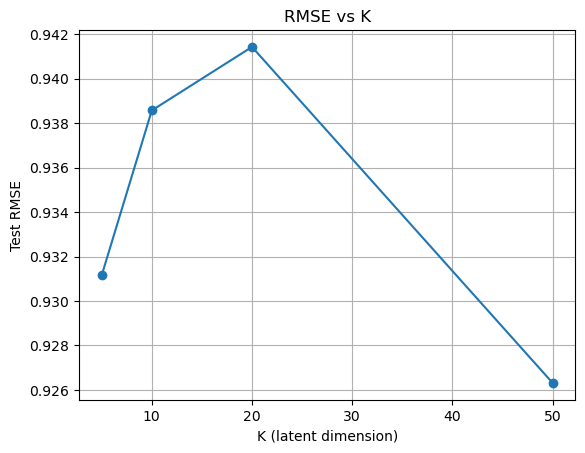

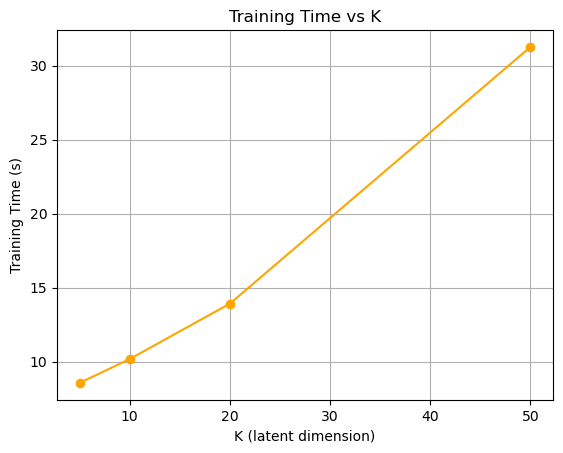

In [8]:
# Hyperparameter Sweep: Test RMSE vs Latent Dimension K
import time
import matplotlib.pyplot as plt

Ks = [5, 10, 20, 50]
rmses = []
times = []

print("Starting hyperparameter sweep over latent dimension K...")
for K in Ks:
    print(f"\n=== K = {K} ===")
    pyro.clear_param_store()
    
    # Define a new PMF model function for this K
    def pmf_model_k(user_ids, item_ids, ratings):
        sigma_u = pyro.param("sigma_u", torch.tensor(1.0), constraint=dist.constraints.positive)
        sigma_v = pyro.param("sigma_v", torch.tensor(1.0), constraint=dist.constraints.positive)
        sigma_r = pyro.param("sigma_r", torch.tensor(1.0), constraint=dist.constraints.positive)

        with pyro.plate("users", Nu):
            U = pyro.sample("U", dist.Normal(torch.zeros(K), sigma_u * torch.ones(K)).to_event(1))
        with pyro.plate("items", Ni):
            V = pyro.sample("V", dist.Normal(torch.zeros(K), sigma_v * torch.ones(K)).to_event(1))
        with pyro.plate("data", len(ratings)):
            u = user_ids.long()
            i = item_ids.long()
            pred = (U[u] * V[i]).sum(-1)
            pyro.sample("obs", dist.Normal(pred, sigma_r), obs=ratings.float())

    # set up guide and SVI
    guide_k = AutoDiagonalNormal(pmf_model_k)
    svi_k = SVI(pmf_model_k, guide_k, Adam({"lr": 5e-3}), Trace_ELBO())

    # training loop on the **training** tensors
    start = time.time()
    for step in range(1, 301):
        loss = svi_k.step(t_train, i_train, r_train)
        if step % 100 == 0:
            print(f"  Training step {step}/300, loss = {loss:.1f}")
    elapsed = time.time() - start
    print(f"  Finished in {elapsed:.1f} sec")

    # evaluation on the **test** tensors
    U_loc = guide_k.median()["U"].detach()
    V_loc = guide_k.median()["V"].detach()
    sse = 0.0
    for j in range(len(r_test)):
        u = t_test[j].item()
        i = i_test[j].item()
        r_true = r_test[j].item()
        r_pred = (U_loc[u] * V_loc[i]).sum().item()
        sse += (r_pred - r_true) ** 2
    rmse = (sse / len(r_test)) ** 0.5
    print(f"  RMSE at K={K}: {rmse:.4f}")

    rmses.append(rmse)
    times.append(elapsed)

# plot RMSE vs K
plt.figure()
plt.plot(Ks, rmses, marker='o')
plt.xlabel('K (latent dimension)')
plt.ylabel('Test RMSE')
plt.title('RMSE vs K')
plt.grid(True)
plt.show()

# plot training time vs K
plt.figure()
plt.plot(Ks, times, marker='o', color='orange')
plt.xlabel('K (latent dimension)')
plt.ylabel('Training Time (s)')
plt.title('Training Time vs K')
plt.grid(True)
plt.show()

Using best latent dimension K = 50

Training on 20% of the data…
  Step 100/300 complete
  Step 200/300 complete
  Step 300/300 complete
  Test RMSE at 20% data: 1.1685 (time 8.8s)

Training on 50% of the data…
  Step 100/300 complete
  Step 200/300 complete
  Step 300/300 complete
  Test RMSE at 50% data: 0.9810 (time 16.7s)

Training on 80% of the data…
  Step 100/300 complete
  Step 200/300 complete
  Step 300/300 complete
  Test RMSE at 80% data: 0.9412 (time 25.5s)



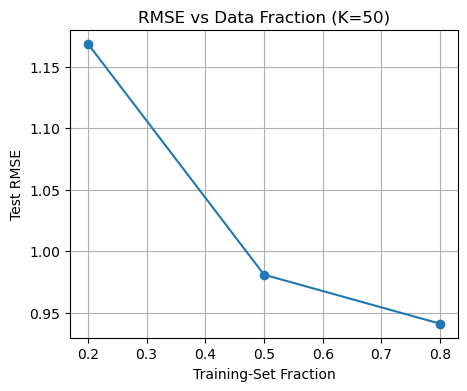

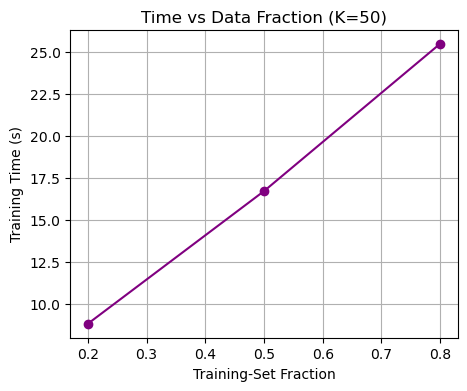

In [9]:
# Hyperparameter Sweep: Test RMSE vs Training‐Set Fraction (best K)
import time
import matplotlib.pyplot as plt

# 1) Find best latent dimension from prior sweep
best_K = Ks[rmses.index(min(rmses))]
print(f"Using best latent dimension K = {best_K}\n")

fractions = [0.2, 0.5, 0.8]
rmse_list = []
time_list = []

for frac in fractions:
    print(f"Training on {int(frac*100)}% of the data…")
    # Subsample
    subset = train_df.sample(frac=frac, random_state=random_seed)
    u_sub = torch.tensor(subset["userId"].values, dtype=torch.long)
    i_sub = torch.tensor(subset["movieId"].values, dtype=torch.long)
    r_sub = torch.tensor(subset["rating"].values, dtype=torch.float)

    # Reset parameters for this run
    pyro.clear_param_store()
    def pmf_frac_model(user_ids, item_ids, ratings):
        sigma_u = pyro.param("sigma_u", torch.tensor(1.0), constraint=dist.constraints.positive)
        sigma_v = pyro.param("sigma_v", torch.tensor(1.0), constraint=dist.constraints.positive)
        sigma_r = pyro.param("sigma_r", torch.tensor(1.0), constraint=dist.constraints.positive)

        with pyro.plate("users", Nu):
            U = pyro.sample("U", dist.Normal(torch.zeros(best_K), sigma_u*torch.ones(best_K)).to_event(1))
        with pyro.plate("items", Ni):
            V = pyro.sample("V", dist.Normal(torch.zeros(best_K), sigma_v*torch.ones(best_K)).to_event(1))
        with pyro.plate("data", len(ratings)):
            u = user_ids.long(); i = item_ids.long()
            pred = (U[u] * V[i]).sum(-1)
            pyro.sample("obs", dist.Normal(pred, sigma_r), obs=ratings.float())

    guide_frac = AutoDiagonalNormal(pmf_frac_model)
    svi_frac   = SVI(pmf_frac_model, guide_frac, Adam({"lr": 5e-3}), Trace_ELBO())

    # Train
    t0 = time.time()
    for step in range(1, 301):
        svi_frac.step(u_sub, i_sub, r_sub)
        if step % 100 == 0:
            print(f"  Step {step}/300 complete")
    elapsed = time.time() - t0
    time_list.append(elapsed)

    # Evaluate on the TEST set
    U_loc = guide_frac.median()["U"].detach()
    V_loc = guide_frac.median()["V"].detach()
    sse = 0.0
    for idx in range(len(r_test)):
        u_idx = t_test[idx].item()
        i_idx = i_test[idx].item()
        true_val = r_test[idx].item()
        pred_val = (U_loc[u_idx] * V_loc[i_idx]).sum().item()
        sse += (pred_val - true_val) ** 2
    rmse = (sse / len(r_test)) ** 0.5
    rmse_list.append(rmse)
    print(f"  Test RMSE at {int(frac*100)}% data: {rmse:.4f} (time {elapsed:.1f}s)\n")

# Plot RMSE vs Training‐Set Fraction
plt.figure(figsize=(5,4))
plt.plot(fractions, rmse_list, marker='o')
plt.xlabel('Training‐Set Fraction')
plt.ylabel('Test RMSE')
plt.title(f'RMSE vs Data Fraction (K={best_K})')
plt.grid(True)
plt.show()

# Plot Training Time vs Training‐Set Fraction
plt.figure(figsize=(5,4))
plt.plot(fractions, time_list, marker='o', color='purple')
plt.xlabel('Training‐Set Fraction')
plt.ylabel('Training Time (s)')
plt.title(f'Time vs Data Fraction (K={best_K})')
plt.grid(True)
plt.show()

In [10]:
# PMF with Added User–Item Bias Terms (using best K)
import time

# Use the best latent factor from previous sweep
do_K = best_K

# Reset stored parameters
pyro.clear_param_store()

# Define the combined model
def pmf_bias_combined(user_ids, item_ids, ratings):
    # Bias terms
    mu = pyro.param("mu", torch.tensor(3.0))
    bu = pyro.param("bu", torch.zeros(Nu))
    bi = pyro.param("bi", torch.zeros(Ni))
    sigma = pyro.param("sigma", torch.tensor(1.0), constraint=dist.constraints.positive)

    # Latent-factor scales
    sigma_u = pyro.param("sigma_u", torch.tensor(1.0), constraint=dist.constraints.positive)
    sigma_v = pyro.param("sigma_v", torch.tensor(1.0), constraint=dist.constraints.positive)

    # User latent vectors
    with pyro.plate("users", Nu):
        U = pyro.sample("U", dist.Normal(torch.zeros(do_K), sigma_u*torch.ones(do_K)).to_event(1))
    # Item latent vectors
    with pyro.plate("items", Ni):
        V = pyro.sample("V", dist.Normal(torch.zeros(do_K), sigma_v*torch.ones(do_K)).to_event(1))

    # Rating likelihood
    with pyro.plate("data", len(ratings)):
        u = user_ids.long()
        i = item_ids.long()
        dot = (U[u] * V[i]).sum(-1)
        pred = mu + bu[u] + bi[i] + dot
        pyro.sample("obs", dist.Normal(pred, sigma), obs=ratings.float())

# Set up the guide and optimizer
guide_combo = AutoDiagonalNormal(pmf_bias_combined)
optimizer   = Adam({"lr":5e-3})
svi_combo   = SVI(pmf_bias_combined, guide_combo, optimizer, loss=Trace_ELBO())

# Train the combined model
print(f"Training PMF+Bias model with K={do_K}...")
start_time = time.time()
for epoch in range(1, 301):
    # changed this line
    svi_combo.step(t_train, i_train, r_train)
    if epoch % 100 == 0:
        print(f"  Epoch {epoch}/300 complete")
elapsed = time.time() - start_time
print(f"Completed training in {elapsed:.1f} seconds\n")

# Evaluate RMSE manually
total_sq = 0.0

# Extract model parameters and latents
U_loc = guide_combo.median()["U"].detach()
V_loc = guide_combo.median()["V"].detach()
bu_   = pyro.param("bu").detach()
bi_   = pyro.param("bi").detach()
mu_   = pyro.param("mu").item()

# changed this line
for idx in range(len(r_test)):
    u_id = t_test[idx].item()
    i_id = i_test[idx].item()

    true = r_test[idx].item()
    pred = mu_ + bu_[u_id] + bi_[i_id] + (U_loc[u_id] * V_loc[i_id]).sum().item()
    total_sq += (pred - true) ** 2

rmse_combined = (total_sq / len(r_test)) ** 0.5
print(f"Combined PMF+Bias RMSE: {rmse_combined:.4f}")
print(f"Delta improvement: {(pmf_rmse - rmse_combined):+.4f}")

Training PMF+Bias model with K=50...
  Epoch 100/300 complete
  Epoch 200/300 complete
  Epoch 300/300 complete
Completed training in 38.9 seconds

Combined PMF+Bias RMSE: 0.8677
Delta improvement: +0.0704


Step 10: train RMSE=1.2827, val RMSE=1.3324
Step 20: train RMSE=1.1573, val RMSE=1.2395
Step 30: train RMSE=1.0590, val RMSE=1.1643
Step 40: train RMSE=0.9785, val RMSE=1.1002
Step 50: train RMSE=0.9138, val RMSE=1.0476
Step 60: train RMSE=0.8667, val RMSE=1.0098
Step 70: train RMSE=0.8327, val RMSE=0.9843
Step 80: train RMSE=0.8065, val RMSE=0.9663
Step 90: train RMSE=0.7846, val RMSE=0.9524
Step 100: train RMSE=0.7654, val RMSE=0.9410
Step 110: train RMSE=0.7485, val RMSE=0.9319
Step 120: train RMSE=0.7336, val RMSE=0.9245
Step 130: train RMSE=0.7201, val RMSE=0.9181
Step 140: train RMSE=0.7084, val RMSE=0.9123
Step 150: train RMSE=0.6984, val RMSE=0.9073
Step 160: train RMSE=0.6898, val RMSE=0.9027
Step 170: train RMSE=0.6825, val RMSE=0.8985
Step 180: train RMSE=0.6768, val RMSE=0.8949
Step 190: train RMSE=0.6724, val RMSE=0.8917
Step 200: train RMSE=0.6691, val RMSE=0.8887
Step 210: train RMSE=0.6666, val RMSE=0.8859
Step 220: train RMSE=0.6649, val RMSE=0.8832
Step 230: train RMS

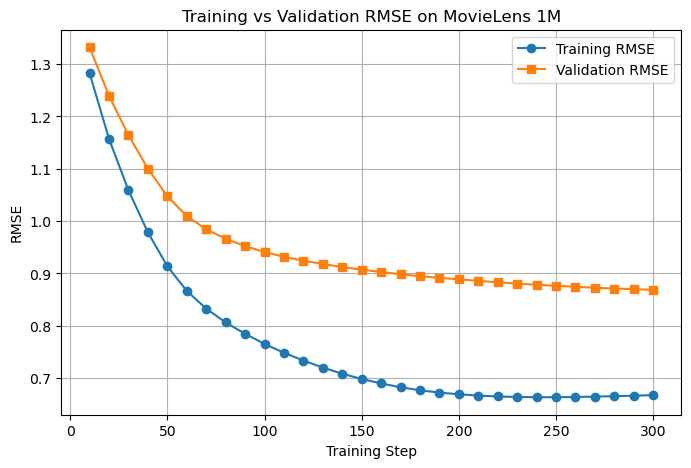

In [11]:
# -------------------------------------------------------------
# Track Training and Validation RMSE During PMF+Bias Training
# -------------------------------------------------------------
import matplotlib.pyplot as plt

# Prepare lists to store RMSE values
train_errors = []
val_errors   = []
steps        = []

# Reset parameters and set up inference *with the combined PMF+Bias model*
pyro.clear_param_store()
guide = AutoDiagonalNormal(pmf_bias_combined)
svi   = SVI(pmf_bias_combined, guide, Adam({"lr":5e-3}), loss=Trace_ELBO())

# Train for a fixed number of steps and record RMSE every 10 steps
total_steps = 300
for step in range(1, total_steps + 1):
    svi.step(t_train, i_train, r_train)      # <-- use your t_train, i_train, r_train
    if step % 10 == 0:
        # Pull out current posterior means & bias params
        with torch.no_grad():
            U_loc = guide.median()["U"]
            V_loc = guide.median()["V"]
            bu_   = pyro.param("bu").detach()
            bi_   = pyro.param("bi").detach()
            mu_   = pyro.param("mu").item()

            # compute RMSE on training set
            preds_tr = mu_ + bu_[t_train] + bi_[i_train] \
                       + (U_loc[t_train] * V_loc[i_train]).sum(dim=1)
            rmse_tr  = ((preds_tr - r_train)**2).mean().sqrt().item()

            # compute RMSE on validation (test) set
            preds_val = mu_ + bu_[t_test] + bi_[i_test] \
                         + (U_loc[t_test] * V_loc[i_test]).sum(dim=1)
            rmse_val  = ((preds_val - r_test)**2).mean().sqrt().item()

        steps.append(step)
        train_errors.append(rmse_tr)
        val_errors.append(rmse_val)
        print(f"Step {step}: train RMSE={rmse_tr:.4f}, val RMSE={rmse_val:.4f}")

# Plot training vs validation error over steps
plt.figure(figsize=(8,5))
plt.plot(steps, train_errors, label='Training RMSE', marker='o')
plt.plot(steps, val_errors,   label='Validation RMSE', marker='s')
plt.title('Training vs Validation RMSE on MovieLens 1M')
plt.xlabel('Training Step')
plt.ylabel('RMSE')
plt.legend()
plt.grid(True)
plt.show()

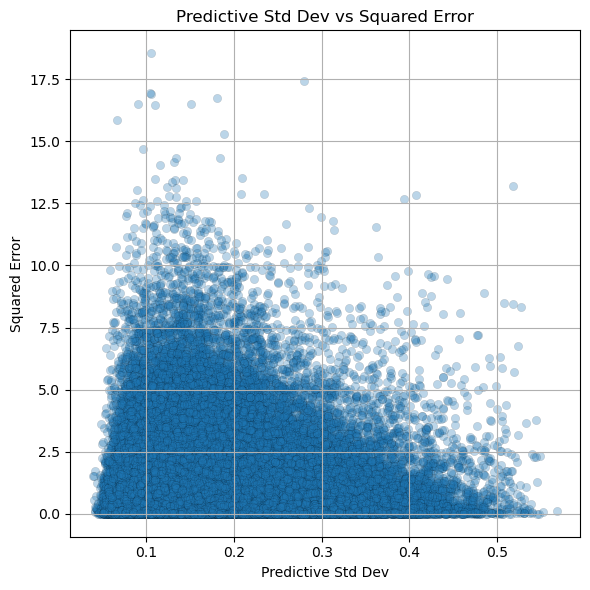

In [12]:
# -------------------------------------------------------------
# Uncertainty Calibration: Scatter Plot of Predictive StdDev vs Squared Error
# -------------------------------------------------------------
import matplotlib.pyplot as plt

std_list   = []
error_list = []

# Pull out everything from your PMF+Bias guide
with torch.no_grad():
    # posterior means
    U_mean = guide_combo.median()["U"].detach()   # shape [Nu, K]
    V_mean = guide_combo.median()["V"].detach()   # shape [Ni, K]
    # posterior stds (diagonal of the guide's scale vector)
    scale_all = guide_combo.scale
    Nu, K     = U_mean.shape
    Ni        = V_mean.shape[0]

    # split that flat scale vector into U_std and V_std
    U_std = scale_all[: Nu * K].reshape(Nu, K)
    V_std = scale_all[Nu * K:].reshape(Ni, K)

    mu_ = pyro.param("mu").item()
    bu_ = pyro.param("bu").detach()
    bi_ = pyro.param("bi").detach()

    # for each test-point, compute sq-error and predictive std
    for idx in range(len(r_test)):
        u = t_test[idx].item()
        i = i_test[idx].item()
        true_r = r_test[idx].item()

        # predictive mean
        mean_pred = mu_ + bu_[u] + bi_[i] + (U_mean[u] * V_mean[i]).sum().item()
        error_list.append((mean_pred - true_r)**2)

        # predictive variance (diagonal approximation)
        var = (U_std[u]**2 * V_std[i]**2).sum().item()
        std_list.append(var**0.5)

# now plot them
plt.figure(figsize=(6,6))
plt.scatter(std_list, error_list, alpha=0.3, edgecolor="k", linewidth=0.2)
plt.title("Predictive Std Dev vs Squared Error")
plt.xlabel("Predictive Std Dev")
plt.ylabel("Squared Error")
plt.grid(True)
plt.tight_layout()
plt.show()